In [3]:
!python -m pip install --user ultralytics opencv-python matplotlib tqdm

In [4]:
import cv2
import matplotlib
import tqdm
from ultralytics import YOLO

print("All libraries installed successfully.")

All libraries installed successfully.


In [6]:
import cv2
import os
from ultralytics import YOLO
from IPython.display import display, clear_output, Video
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
MODEL_NAME = "yolov8n.pt"

CONFIDENCE_THRESHOLD = 0.40

OUTPUT_VIDEO_PATH = "border_monitoring_output.mp4"

DISPLAY_IN_NOTEBOOK = True

DISPLAY_EVERY_N_FRAMES = 10

print("Configuration set successfully.")

Configuration set successfully.


In [11]:
folder_path = r"C:\Users\RAYMONDMUSTWIN\Documents\Surveillance project"

print("Files in folder:")

for file in os.listdir(folder_path):
    print(file)


Files in folder:
.ipynb_checkpoints
AI_Drone_Border_Monitoring.ipynb
demo_video.mp4
Human detection program.ipynb
Untitled.ipynb
yolov8n.pt


In [12]:
VIDEO_PATH = r"C:\Users\RAYMONDMUSTWIN\Documents\Surveillance project\demo_video.mp4"

if not os.path.exists(VIDEO_PATH):
    raise FileNotFoundError(f"Video file not found: {VIDEO_PATH}")

print("Video loaded successfully:", VIDEO_PATH)

Video loaded successfully: C:\Users\RAYMONDMUSTWIN\Documents\Surveillance project\demo_video.mp4


In [13]:
model = YOLO(MODEL_NAME)

print("YOLOv8 model loaded successfully")

YOLOv8 model loaded successfully


In [14]:
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Error: Could not open video file.")

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if fps == 0:
    fps = 25

print("Video Properties")
print("Width:", frame_width)
print("Height:", frame_height)
print("FPS:", fps)
print("Total Frames:", total_frames)

Video Properties
Width: 576
Height: 1024
FPS: 28.681318681318682
Total Frames: 174


In [15]:
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    OUTPUT_VIDEO_PATH,
    fourcc,
    fps,
    (frame_width, frame_height)
)

if not out.isOpened():
    raise RuntimeError("Error: Could not create output video file.")

print("Output video writer created successfully")

Output video writer created successfully


In [16]:
def show_frame_in_notebook(frame, title="Border Area Monitoring System"):
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 7))
    plt.imshow(frame_rgb)
    plt.title(title)
    plt.axis("off")
    plt.show()

print("Display function created successfully.")

Display function created successfully.


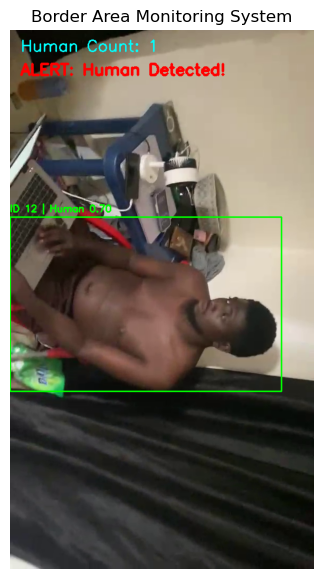

Video processing completed successfully.
Output saved as: border_monitoring_output.mp4


In [17]:
frame_number = 0

try:
    progress_bar = tqdm(total=total_frames, desc="Processing Video")

    while cap.isOpened():
        ret, frame = cap.read()

        if not ret:
            break

        frame_number += 1
        human_count = 0

        results = model.track(
            frame,
            persist=True,
            classes=[0],
            conf=CONFIDENCE_THRESHOLD,
            tracker="bytetrack.yaml",
            verbose=False
        )

        if results and results[0].boxes is not None:
            boxes = results[0].boxes

            for box in boxes:
                human_count += 1

                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
                confidence = float(box.conf[0])

                track_id = None
                if box.id is not None:
                    track_id = int(box.id[0])

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                label = f"Human {confidence:.2f}"

                if track_id is not None:
                    label = f"ID {track_id} | Human {confidence:.2f}"

                cv2.putText(
                    frame,
                    label,
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 255, 0),
                    2
                )

        cv2.putText(
            frame,
            f"Human Count: {human_count}",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 255, 0),
            2
        )

        if human_count > 0:
            cv2.putText(
                frame,
                "ALERT: Human Detected!",
                (20, 85),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (0, 0, 255),
                3
            )

        out.write(frame)

        if DISPLAY_IN_NOTEBOOK and frame_number % DISPLAY_EVERY_N_FRAMES == 0:
            clear_output(wait=True)
            show_frame_in_notebook(frame)

        progress_bar.update(1)

finally:
    cap.release()
    out.release()
    progress_bar.close()

print("Video processing completed successfully.")
print("Output saved as:", OUTPUT_VIDEO_PATH)

In [20]:
import os

print("Output video exists:", os.path.exists(OUTPUT_VIDEO_PATH))
print("Output video size:", os.path.getsize(OUTPUT_VIDEO_PATH), "bytes")

Output video exists: True
Output video size: 3505362 bytes


In [ ]:
print(os.path.abspath(converted_video_path))

In [24]:
import os

print(os.path.abspath(OUTPUT_VIDEO_PATH))

C:\Users\RAYMONDMUSTWIN\border_monitoring_output.mp4
